# Aging brain MERFISH: spatial/reference sanity checks

Diagnose the near-zero gene-wise variance correlation seen in `context_analysis/VariancePreservation.ipynb`. Start with one final slice; optionally scan all 12. This notebook reads existing files and writes no results. It checks provenance, matrix/label alignment, cell and gene coverage, mapped-reference reuse, matched-cell-type expression profiles, and genes driving disagreement. Correlation alone cannot establish which file is wrong.

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import scipy.sparse as sp
from scipy.stats import spearmanr
import anndata as ad
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

ROOT = Path('/work/magroup/skrieger/Syndri/data/datasets/agingbrain_merfish')
FINAL_DIR = ROOT / 'results/final'
POOLED_REFERENCE = ROOT / 'interim/single-cell/sc_integrated_mapped-donors5to8.h5ad'
SLICE_PATH = sorted(FINAL_DIR.glob('*.h5ad'))[0]  # Change to another final slice if desired.
RUN_ALL_SLICES = False  # Set True to compute the compact summary across all 12 slices.
MIN_ST_CELLS = 50
MIN_SC_CELLS = 50
MIN_REF_DETECTION = 0.05
MARKER_GENES = ['Drd1', 'Drd2', 'Pde10a', 'Slc17a6', 'Mbp', 'Crispld1']

assert SLICE_PATH.exists() and POOLED_REFERENCE.exists()
print('Selected slice:', SLICE_PATH)
print('Final slices:', len(list(FINAL_DIR.glob('*.h5ad'))))

Selected slice: /work/magroup/skrieger/Syndri/data/datasets/agingbrain_merfish/results/final/st_integrated_MsBrainAgingSpatialDonor_5_0.h5ad
Final slices: 12


In [2]:
def dense(X):
    return X.toarray() if sp.issparse(X) else np.asarray(X)


def normalized_log_counts(X, target_sum=10000):
    X = dense(X).astype(np.float64, copy=True)
    totals = X.sum(axis=1)
    X *= np.divide(target_sum, totals, out=np.zeros_like(totals), where=totals > 0)[:, None]
    np.log1p(X, out=X)
    return X


def rho(a, b):
    result = spearmanr(a, b).statistic
    return float(result) if np.isfinite(result) else np.nan


def donor_reference_path(spatial):
    metadata = spatial.uns.get('rctd_run_metadata_X', {})
    path = metadata.get('reference_file')
    if not path:
        raise KeyError('Missing rctd_run_metadata_X.reference_file')
    return Path(path)


def gene_indexer(source, target):
    if not source.var_names.is_unique or not target.var_names.is_unique:
        raise ValueError('Gene IDs must be unique')
    common = source.var_names.intersection(target.var_names)
    if len(common) == 0:
        raise ValueError('No matching gene IDs')
    return common, source.var_names.get_indexer(common), target.var_names.get_indexer(common)


def matrix_summary(adata, name):
    X = dense(adata.X)
    totals = X.sum(axis=1)
    return dict(matrix=name, cells=adata.n_obs, genes=adata.n_vars,
                mean_counts_per_cell=float(totals.mean()),
                median_counts_per_cell=float(np.median(totals)),
                zero_fraction=float(np.mean(X == 0)),
                noninteger_fraction=float(np.mean(np.abs(X - np.rint(X)) > 1e-5)))

## Provenance and file alignment

The RCTD metadata specifies the donor reference actually used for this slice. The source spatial file tests whether the mismatch was introduced when the final AnnData was assembled. The donor references were subset from `sc_integrated_agematched.h5ad`. The pooled mapped reference was built later and may reuse source single-cell IDs; its row count is therefore not necessarily its number of independent cells.

In [3]:
spatial = ad.read_h5ad(SLICE_PATH)
donor_path = donor_reference_path(spatial)
donor_ref = ad.read_h5ad(donor_path)
pooled_ref = ad.read_h5ad(POOLED_REFERENCE)
source_path = Path(spatial.uns['rctd_run_metadata_X']['spatial_file'])
source_spatial = ad.read_h5ad(source_path)

print('Source spatial:', source_path)
print('Donor reference:', donor_path)
print('Pooled mapped reference:', POOLED_REFERENCE)
print('Final/source cell IDs equal:', spatial.obs_names.equals(source_spatial.obs_names))
print('Final/source gene IDs equal:', spatial.var_names.equals(source_spatial.var_names))
print('Final/source raw X equal:', np.array_equal(dense(spatial.X), dense(source_spatial.X)))
for label in ['cell_type', 'cell_type_annot', 'clust_annot']:
    if label in spatial.obs and label in source_spatial.obs:
        print(f'Final/source {label} equal:', spatial.obs[label].equals(source_spatial.obs[label]))

display(pd.DataFrame([
    matrix_summary(spatial, 'spatial'), matrix_summary(donor_ref, 'donor reference'),
    matrix_summary(pooled_ref, 'pooled mapped reference')
]).set_index('matrix'))
display(pd.DataFrame({
    'spatial_vs_donor': [spatial.var_names.equals(donor_ref.var_names),
                         spatial.var_names.is_unique and donor_ref.var_names.is_unique],
    'spatial_vs_pooled': [spatial.var_names.equals(pooled_ref.var_names),
                          spatial.var_names.is_unique and pooled_ref.var_names.is_unique],
}, index=['gene_ID_order_equal', 'gene_IDs_unique']))

for name, ref in [('donor', donor_ref), ('pooled', pooled_ref)]:
    if 'source_sc_id' in ref.obs:
        print(f'{name} mapped rows: {ref.n_obs:,}; unique source_sc_id: '
              f"{ref.obs['source_sc_id'].nunique():,}")
    else:
        print(f'{name}: no source_sc_id column')
del source_spatial

Source spatial: /work/magroup/skrieger/Syndri/data/datasets/agingbrain_merfish/interim/spatial/st_integrated_MsBrainAgingSpatialDonor_5_0.h5ad
Donor reference: /work/magroup/skrieger/Syndri/data/datasets/agingbrain_merfish/interim/single-cell/rctd_donor_references/reference_donor_5.h5ad
Pooled mapped reference: /work/magroup/skrieger/Syndri/data/datasets/agingbrain_merfish/interim/single-cell/sc_integrated_mapped-donors5to8.h5ad
Final/source cell IDs equal: True
Final/source gene IDs equal: True
Final/source raw X equal: True
Final/source cell_type equal: True
Final/source cell_type_annot equal: True
Final/source clust_annot equal: True


,cells,genes,mean_counts_per_cell,median_counts_per_cell,zero_fraction,noninteger_fraction
matrix,,,,,,
spatial,10744,374,154.131424,148.0,0.845464,0.0
donor reference,21728,374,412.069855,363.0,0.803192,0.0
pooled mapped reference,126408,374,411.153290,349.0,0.807783,0.0


,spatial_vs_donor,spatial_vs_pooled
gene_ID_order_equal,True,True
gene_IDs_unique,True,True


donor: no source_sc_id column
pooled mapped rows: 126,408; unique source_sc_id: 41,031


## Match cell-type labels and compare reference versions

Compare the donor reference against the pooled mapped file restricted to the same donor. Strong donor-versus-pooled agreement alongside weak spatial-versus-reference agreement would rule out the choice of these two references as the main explanation.

In [4]:
def label_counts(adata, name):
    return adata.obs['cell_type'].astype(str).value_counts().rename(name)


display(pd.concat([
    label_counts(spatial, 'spatial'), label_counts(donor_ref, 'donor reference'),
    label_counts(pooled_ref, 'pooled mapped reference')
], axis=1).fillna(0).astype(int))

donor_match = re.search(r'reference_donor_(\d+)\.h5ad$', donor_path.name)
donor_number = donor_match.group(1) if donor_match else None
pooled_same_donor = pooled_ref
if donor_number and 'donor_id' in pooled_ref.obs:
    mask = pooled_ref.obs['donor_id'].astype(str).str.endswith(f'Donor_{donor_number}').to_numpy()
    pooled_same_donor = pooled_ref[mask]
    print('Pooled mapped rows for this donor:', pooled_same_donor.n_obs)

shared = spatial.var_names.intersection(donor_ref.var_names).intersection(pooled_same_donor.var_names)
assert len(shared) > 0
st_gene_idx = spatial.var_names.get_indexer(shared)
dr_gene_idx = donor_ref.var_names.get_indexer(shared)
pr_gene_idx = pooled_same_donor.var_names.get_indexer(shared)
st_mean = dense(spatial.X[:, st_gene_idx]).mean(axis=0)
dr_mean = dense(donor_ref.X[:, dr_gene_idx]).mean(axis=0)
pr_mean = dense(pooled_same_donor.X[:, pr_gene_idx]).mean(axis=0)
display(pd.DataFrame({'comparison': ['spatial vs donor', 'spatial vs pooled, same donor',
                                     'donor vs pooled, same donor'],
                      'gene_mean_rho': [rho(st_mean, dr_mean), rho(st_mean, pr_mean),
                                        rho(dr_mean, pr_mean)]}))

,spatial,donor reference,pooled mapped reference
cell_type,,,
oligodendrocyte,2661,2729,22222
neuron,2616,9228,32181
medium spiny neuron,1827,3467,24008
astrocyte,1112,2017,13139
endothelial cell,825,114,10869
inhibitory interneuron,593,1942,9112
microglial cell,436,811,5783
pericyte,302,104,3458
oligodendrocyte precursor cell,216,1013,3661


Pooled mapped rows for this donor: 29371


,comparison,gene_mean_rho
0,spatial vs donor,-0.075205
1,"spatial vs pooled, same donor",-0.065889
2,"donor vs pooled, same donor",0.983538


## Per-cell-type gene correlations

Use the same 10,000-count log normalization and reference detection filter as the variance notebook. Also show correlations of raw gene means and detection rates. If all three are low before correction, the issue is already present in the input matrices.

In [5]:
def compare_cell_types(spatial, reference, reference_name, min_st=MIN_ST_CELLS,
                       min_sc=MIN_SC_CELLS, min_detection=MIN_REF_DETECTION):
    common, st_idx, ref_idx = gene_indexer(spatial, reference)
    st_X = dense(spatial.X[:, st_idx])
    ref_X = dense(reference.X[:, ref_idx])
    st_norm = normalized_log_counts(st_X)
    ref_norm = normalized_log_counts(ref_X)
    st_labels = spatial.obs['cell_type'].astype(str).to_numpy()
    ref_labels = reference.obs['cell_type'].astype(str).to_numpy()
    rows = []
    for cell_type in sorted(set(st_labels) & set(ref_labels)):
        st_mask = st_labels == cell_type
        ref_mask = ref_labels == cell_type
        if st_mask.sum() < min_st or ref_mask.sum() < min_sc:
            continue
        ref_detection = (ref_X[ref_mask] > 0).mean(axis=0)
        ref_var = ref_norm[ref_mask].var(axis=0)
        keep = (ref_detection >= min_detection) & (ref_var > 0)
        if keep.sum() < 2:
            continue
        rows.append({
            'reference': reference_name, 'cell_type': cell_type,
            'n_spatial': int(st_mask.sum()), 'n_reference': int(ref_mask.sum()),
            'n_genes': int(keep.sum()),
            'variance_rho': rho(st_norm[st_mask].var(axis=0)[keep], ref_var[keep]),
            'mean_rho': rho(st_X[st_mask].mean(axis=0)[keep], ref_X[ref_mask].mean(axis=0)[keep]),
            'detection_rho': rho((st_X[st_mask] > 0).mean(axis=0)[keep], ref_detection[keep]),
        })
    return pd.DataFrame(rows)


correlations = pd.concat([
    compare_cell_types(spatial, donor_ref, 'donor'),
    compare_cell_types(spatial, pooled_same_donor, 'pooled, same donor'),
], ignore_index=True)
display(correlations.sort_values(['cell_type', 'reference']).reset_index(drop=True))
display(correlations.groupby('reference')[['variance_rho', 'mean_rho', 'detection_rho']]
        .median())

,reference,cell_type,n_spatial,n_reference,n_genes,variance_rho,mean_rho,detection_rho
0,donor,astrocyte,1112,2017,176,0.093187,0.049855,0.058964
1,"pooled, same donor",astrocyte,1112,3014,169,0.112665,0.063970,0.076652
2,donor,cell,56,154,180,-0.040456,0.015526,0.002277
3,"pooled, same donor",cell,56,143,179,-0.054318,0.022499,-0.006511
4,donor,endothelial cell,825,114,198,0.078456,0.032385,0.079183
5,"pooled, same donor",endothelial cell,825,2268,206,-0.005003,-0.045101,-0.012110
6,donor,inhibitory interneuron,593,1942,186,0.071212,0.013953,0.010415
7,"pooled, same donor",inhibitory interneuron,593,1721,185,0.066499,0.011474,0.005519
8,donor,medium spiny neuron,1827,3467,157,0.021772,-0.070474,-0.081258
9,"pooled, same donor",medium spiny neuron,1827,3509,156,-0.003199,-0.077282,-0.085905


,variance_rho,mean_rho,detection_rho
reference,,,
donor,0.021772,0.015526,0.010415
"pooled, same donor",0.012387,0.011474,0.005519


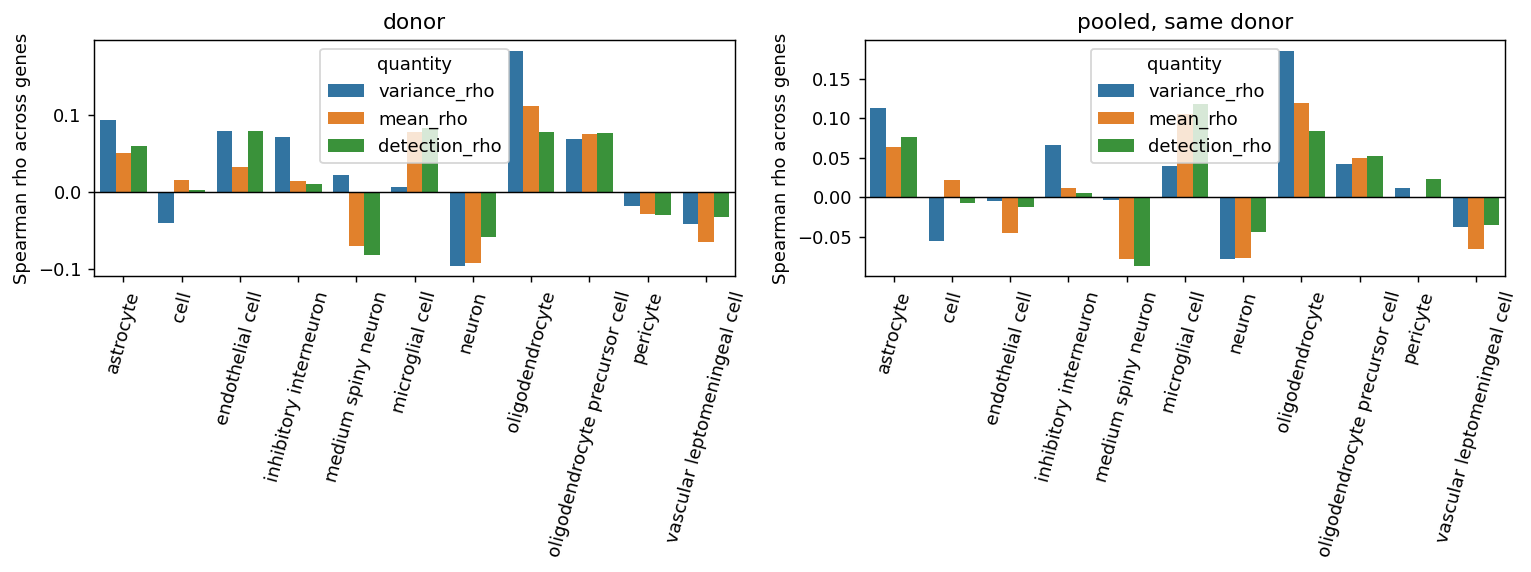

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), dpi=130)
for ax, reference_name in zip(axes, ['donor', 'pooled, same donor']):
    subset = correlations.loc[correlations.reference.eq(reference_name)]
    long = subset.melt(id_vars='cell_type', value_vars=['variance_rho', 'mean_rho',
                                                        'detection_rho'],
                       var_name='quantity', value_name='rho')
    sns.barplot(data=long, x='cell_type', y='rho', hue='quantity', ax=ax)
    ax.axhline(0, color='black', lw=0.8)
    ax.set_title(reference_name)
    ax.set_xlabel('')
    ax.set_ylabel('Spearman rho across genes')
    ax.tick_params(axis='x', rotation=75)
fig.tight_layout()
plt.show()

## Gene-level and marker checks

The scatterplots reveal broad rank disagreement and outlier genes. Marker profiles test whether a gene has similar relative cell-type enrichment across assays; a low correlation here can arise from annotation differences, assay effects, or upstream matrix alignment. Inspect the gene table before assigning a cause.

,gene_id,gene_name,spatial_mean,reference_mean,spatial_detection,reference_detection,spatial_log_variance,reference_log_variance,log2_mean_ratio
59,ENSMUSG00000023868,Pde10a,0.044676,24.196520,0.043187,0.887012,0.701573,4.581119,-8.790270
341,ENSMUSG00000032238,Rora,0.033972,18.898149,0.032669,0.904225,0.552379,3.877123,-8.748193
53,ENSMUSG00000030209,Grin2b,0.064687,23.057760,0.062174,0.891522,1.003805,4.365551,-8.270800
82,ENSMUSG00000078591,Hs3st4,0.043280,12.435797,0.041139,0.679262,0.683792,6.713656,-7.867849
320,ENSMUSG00000074968,Ano3,0.014054,5.477863,0.013682,0.680781,0.226242,5.535423,-7.833802
157,ENSMUSG00000025776,Crispld1,28.755863,0.116670,0.734270,0.066596,10.060773,0.753461,7.827142
322,ENSMUSG00000061911,Myt1l,0.057800,14.215574,0.054821,0.828010,0.871267,5.143970,-7.712992
226,ENSMUSG00000041872,Il17f,2.064687,0.000322,0.542722,0.000322,7.239527,0.004052,7.651004
63,ENSMUSG00000051439,Cd14,2.131608,0.003084,0.402178,0.002946,6.978487,0.049970,7.354794
58,ENSMUSG00000022708,Zbtb20,0.042628,7.737206,0.039650,0.780698,0.675568,5.745224,-7.201690


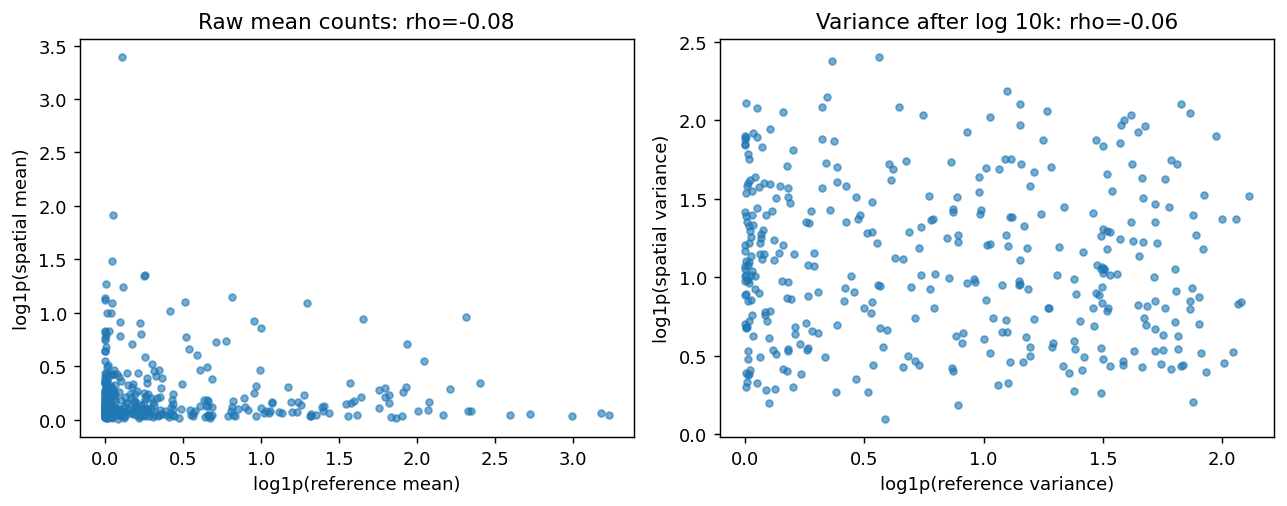

In [7]:
common, st_idx, ref_idx = gene_indexer(spatial, donor_ref)
st_X = dense(spatial.X[:, st_idx]); ref_X = dense(donor_ref.X[:, ref_idx])
st_norm = normalized_log_counts(st_X); ref_norm = normalized_log_counts(ref_X)
gene_table = pd.DataFrame({
    'gene_id': common,
    'gene_name': spatial.var.iloc[st_idx]['feature_name'].astype(str).to_numpy()
                 if 'feature_name' in spatial.var else common,
    'spatial_mean': st_X.mean(axis=0), 'reference_mean': ref_X.mean(axis=0),
    'spatial_detection': (st_X > 0).mean(axis=0),
    'reference_detection': (ref_X > 0).mean(axis=0),
    'spatial_log_variance': st_norm.var(axis=0),
    'reference_log_variance': ref_norm.var(axis=0),
})
gene_table['log2_mean_ratio'] = np.log2((gene_table.spatial_mean + 0.01) /
                                        (gene_table.reference_mean + 0.01))
display(gene_table.reindex(gene_table.log2_mean_ratio.abs().sort_values(ascending=False).index).head(20))

fig, axes = plt.subplots(1, 2, figsize=(10, 4), dpi=130)
for ax, x, y, title in [
    (axes[0], 'reference_mean', 'spatial_mean', 'Raw mean counts'),
    (axes[1], 'reference_log_variance', 'spatial_log_variance', 'Variance after log 10k'),
]:
    ax.scatter(np.log1p(gene_table[x]), np.log1p(gene_table[y]), s=14, alpha=0.6)
    ax.set_xlabel(f'log1p(reference {x.split("_")[-1]})')
    ax.set_ylabel(f'log1p(spatial {y.split("_")[-1]})')
    ax.set_title(f'{title}: rho={rho(gene_table[x], gene_table[y]):.2f}')
fig.tight_layout()
plt.show()

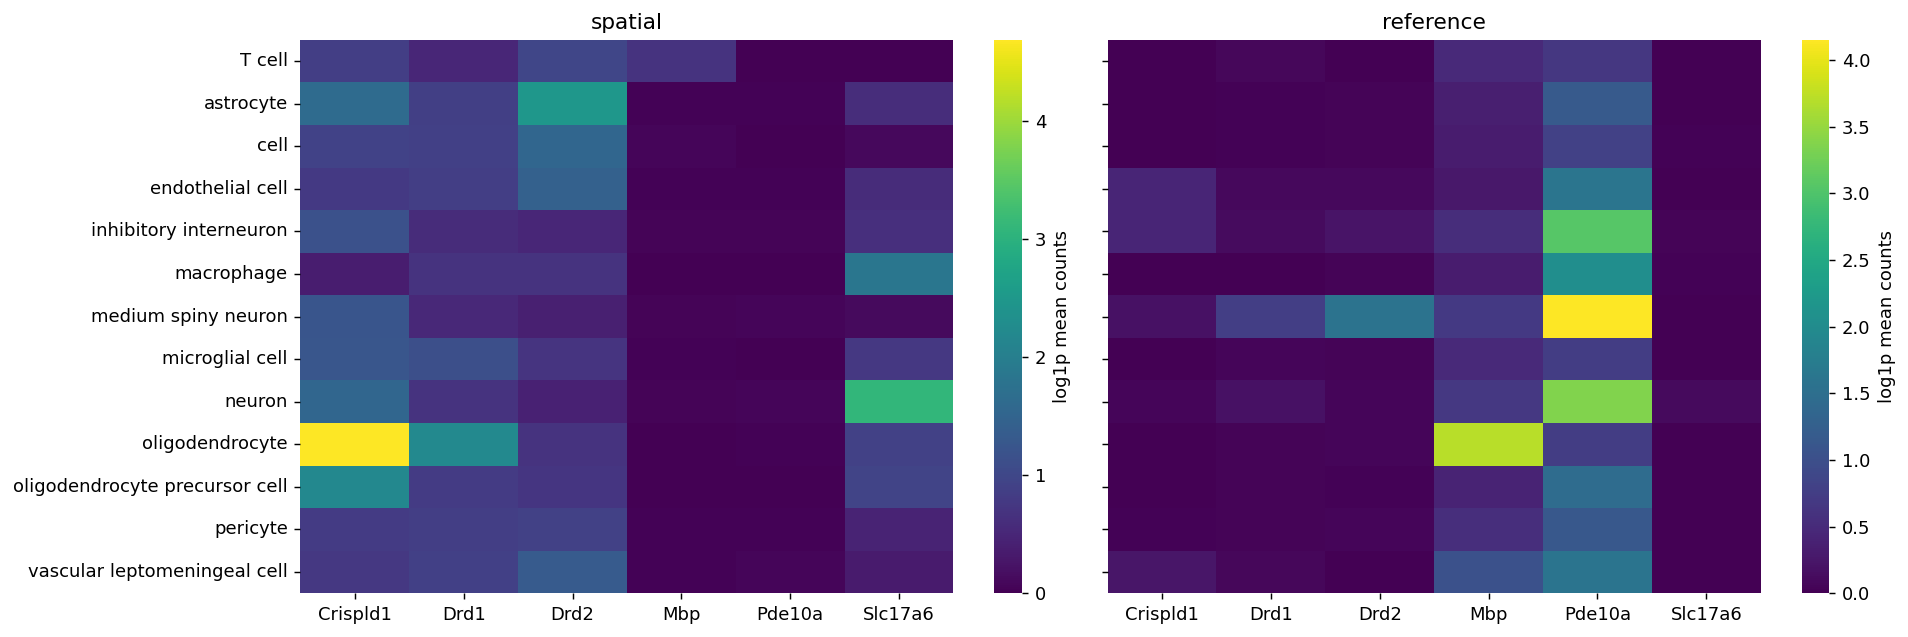

,gene,cell_type,spatial_mean,reference_mean,spatial_detection,reference_detection
0,Drd1,T cell,0.666667,0.076923,0.333333,0.076923
1,Drd1,astrocyte,1.375899,0.030739,0.587230,0.029251
2,Drd1,cell,1.446429,0.032468,0.750000,0.032468
3,Drd1,endothelial cell,1.338182,0.087719,0.675152,0.061404
4,Drd1,inhibitory interneuron,0.774030,0.123584,0.497470,0.111226
...,...,...,...,...,...,...
73,Crispld1,neuron,3.588685,0.066320,0.695336,0.045297
74,Crispld1,oligodendrocyte,107.063889,0.010993,0.999624,0.010993
75,Crispld1,oligodendrocyte precursor cell,7.953704,0.010859,0.870370,0.009872
76,Crispld1,pericyte,1.264901,0.019231,0.549669,0.019231


In [8]:
marker_rows = []
st_labels = spatial.obs['cell_type'].astype(str).to_numpy()
ref_labels = donor_ref.obs['cell_type'].astype(str).to_numpy()
for gene in MARKER_GENES:
    matches = np.flatnonzero(gene_table.gene_name.eq(gene).to_numpy())
    if len(matches) != 1:
        print(f'Skipping {gene}: found {len(matches)} matches')
        continue
    j = matches[0]
    for cell_type in sorted(set(st_labels) & set(ref_labels)):
        s = st_labels == cell_type
        t = ref_labels == cell_type
        marker_rows.append({'gene': gene, 'cell_type': cell_type,
                            'spatial_mean': st_X[s, j].mean(),
                            'reference_mean': ref_X[t, j].mean(),
                            'spatial_detection': (st_X[s, j] > 0).mean(),
                            'reference_detection': (ref_X[t, j] > 0).mean()})
marker_df = pd.DataFrame(marker_rows)
fig, axes = plt.subplots(1, 2, figsize=(15, 5), dpi=130, sharey=True)
for ax, source in zip(axes, ['spatial', 'reference']):
    table = marker_df.pivot(index='cell_type', columns='gene', values=f'{source}_mean')
    sns.heatmap(np.log1p(table), cmap='viridis', ax=ax, cbar_kws={'label': 'log1p mean counts'})
    ax.set_title(source)
    ax.set_xlabel('')
    ax.set_ylabel('')
fig.tight_layout()
plt.show()
display(marker_df)

## Compare against the original `raw` files

The two raw files are the upstream spatial and single-cell AnnData objects. Compare by **cell ID and gene ID**, then separately test whether the final spatial matrix retained the raw matrix's original column order while its gene labels were reordered. The latter is a gene-to-count mismatch even when both matrices have the same shape and gene set. The formatting notebook first subsets spatial genes using `gene_overlap`, then assigns `st_data.X = st_data.raw.X`; the raw matrix is not indexed into that new gene order.

In [ ]:
RAW_SPATIAL = ROOT / 'raw/spatial/c93d78c2-ee17-4504-8d1c-17cf093ad7b5.h5ad'
RAW_SINGLE_CELL = ROOT / 'raw/single-cell/752ed29d-bbb0-45bd-9c57-19edf68ef73e.h5ad'
raw_spatial = ad.read_h5ad(RAW_SPATIAL, backed='r')
raw_sc = ad.read_h5ad(RAW_SINGLE_CELL, backed='r')

assert spatial.obs_names.is_unique and donor_ref.obs_names.is_unique
assert raw_spatial.obs_names.is_unique and raw_sc.obs_names.is_unique
spatial_rows = raw_spatial.obs_names.get_indexer(spatial.obs_names)
sc_rows = raw_sc.obs_names.get_indexer(donor_ref.obs_names)
assert (spatial_rows >= 0).all() and (sc_rows >= 0).all()
raw_spatial_genes = raw_spatial.raw.var_names
raw_sc_genes = raw_sc.raw.var_names
assert raw_spatial_genes.is_unique and raw_sc_genes.is_unique
assert set(spatial.var_names) == set(raw_spatial_genes)
assert set(donor_ref.var_names).issubset(raw_sc_genes)

# The spatial raw matrix is only 374 genes, so all selected rows fit in memory.
raw_spatial_counts = dense(raw_spatial.raw.X[spatial_rows, :])
stored_spatial_counts = dense(spatial.X)
raw_gene_index = raw_spatial_genes.get_indexer(spatial.var_names)
aligned_spatial_counts = raw_spatial_counts[:, raw_gene_index]

print('Spatial final X == raw spatial counts by raw column position:',
      np.array_equal(stored_spatial_counts, raw_spatial_counts))
print('Spatial final X == raw spatial counts aligned by gene ID:',
      np.array_equal(stored_spatial_counts, aligned_spatial_counts))
print('Spatial gene-label positions unchanged from raw:',
      int((spatial.var_names.to_numpy() == raw_spatial_genes.to_numpy()).sum()),
      'of', spatial.n_vars)
print('Cell counts preserved:', np.array_equal(stored_spatial_counts.sum(axis=1),
                                                aligned_spatial_counts.sum(axis=1)))

display(pd.DataFrame({
    'final_column': np.arange(min(12, spatial.n_vars)),
    'final_gene_name': spatial.var['feature_name'].iloc[:12].to_numpy(),
    'gene_name_of_raw_count_in_that_column':
        raw_spatial.raw.var['feature_name'].iloc[:12].to_numpy(),
}))

# Sample the original single-cell raw matrix. Its 20,929 genes are too large
# to load for every cell; the donor reference contains only the 374-gene panel.
sample = np.linspace(0, donor_ref.n_obs - 1, num=min(100, donor_ref.n_obs), dtype=int)
sc_source_rows = sc_rows[sample]
sc_raw_gene_index = raw_sc_genes.get_indexer(donor_ref.var_names)
sc_raw_sample = dense(raw_sc.raw.X[sc_source_rows, :])[:, sc_raw_gene_index]
print('Donor reference X == original single-cell raw counts '
      f'for {len(sample)} sampled cells and all {donor_ref.n_vars} genes:',
      np.array_equal(dense(donor_ref.X[sample, :]), sc_raw_sample))

raw_spatial.file.close()
raw_sc.file.close()

### Check every final slice against the raw spatial file

Sample 32 matched cells from each final slice. This checks whether the same positional count/gene-label mismatch appears across all donors without loading every count matrix into memory.

In [ ]:
raw_spatial = ad.read_h5ad(RAW_SPATIAL, backed='r')
audit_rows = []
for path in sorted(FINAL_DIR.glob('*.h5ad')):
    final = ad.read_h5ad(path, backed='r')
    sample = np.linspace(0, final.n_obs - 1, num=min(32, final.n_obs), dtype=int)
    raw_rows = raw_spatial.obs_names.get_indexer(final.obs_names[sample])
    if (raw_rows < 0).any():
        raise ValueError(f'{path}: missing cell IDs in raw spatial file')
    raw_counts = dense(raw_spatial.raw.X[raw_rows, :])
    final_counts = dense(final.X[sample, :])
    gene_idx = raw_spatial.raw.var_names.get_indexer(final.var_names)
    if (gene_idx < 0).any():
        raise ValueError(f'{path}: missing gene IDs in raw spatial file')
    audit_rows.append({
        'slice': path.stem,
        'sampled_cells': len(sample),
        'positionally_equal': np.array_equal(final_counts, raw_counts),
        'gene_aligned_equal': np.array_equal(final_counts, raw_counts[:, gene_idx]),
        'unchanged_gene_positions': int((final.var_names.to_numpy() ==
                                         raw_spatial.raw.var_names.to_numpy()).sum()),
    })
    final.file.close()
raw_spatial.file.close()
raw_slice_audit = pd.DataFrame(audit_rows)
display(raw_slice_audit)
display(raw_slice_audit[['positionally_equal', 'gene_aligned_equal']].value_counts())

## Effect of aligning the spatial counts by gene ID

Repair the selected slice **in memory only** using the raw spatial counts indexed by gene ID. Compare it with the stored final matrix against the same donor reference. This isolates the column-label problem; remaining low correlations can still reflect spatial versus scRNA-seq assay differences, cell annotations, or other upstream issues.

In [ ]:
aligned_spatial = spatial.copy()
aligned_spatial.X = aligned_spatial_counts
stored_corr = compare_cell_types(spatial, donor_ref, 'stored final')
aligned_corr = compare_cell_types(aligned_spatial, donor_ref, 'raw aligned by gene ID')
raw_comparison = pd.concat([stored_corr, aligned_corr], ignore_index=True)
display(raw_comparison.pivot(index='cell_type', columns='reference',
                             values=['variance_rho', 'mean_rho', 'detection_rho']))
display(raw_comparison.groupby('reference')[['variance_rho', 'mean_rho', 'detection_rho']]
        .median())

marker_comparison = []
for gene in MARKER_GENES:
    matches = np.flatnonzero(gene_table.gene_name.eq(gene).to_numpy())
    if len(matches) != 1:
        continue
    j = matches[0]
    for cell_type in sorted(set(st_labels) & set(ref_labels)):
        s = st_labels == cell_type
        t = ref_labels == cell_type
        marker_comparison.extend([
            {'gene': gene, 'cell_type': cell_type, 'source': 'stored final',
             'mean': stored_spatial_counts[s, j].mean()},
            {'gene': gene, 'cell_type': cell_type, 'source': 'raw aligned by gene ID',
             'mean': aligned_spatial_counts[s, j].mean()},
            {'gene': gene, 'cell_type': cell_type, 'source': 'donor reference',
             'mean': ref_X[t, j].mean()},
        ])
marker_comparison = pd.DataFrame(marker_comparison)
fig, axes = plt.subplots(1, 3, figsize=(18, 5), dpi=130, sharey=True)
for ax, source in zip(axes, ['stored final', 'raw aligned by gene ID', 'donor reference']):
    table = marker_comparison.query('source == @source').pivot(
        index='cell_type', columns='gene', values='mean')
    sns.heatmap(np.log1p(table), cmap='viridis', ax=ax,
                cbar_kws={'label': 'log1p mean counts'})
    ax.set_title(source)
    ax.set_xlabel('')
    ax.set_ylabel('')
fig.tight_layout()
plt.show()

## Optional all-slice summary

Set `RUN_ALL_SLICES=True` in the first code cell to compute raw variance and mean correlations for every slice with its RCTD donor reference. It loads one donor reference at a time. This establishes whether the mismatch is isolated or present across donors.

In [9]:
if RUN_ALL_SLICES:
    all_rows = []
    cached_path = None
    cached_ref = None
    for path in sorted(FINAL_DIR.glob('*.h5ad')):
        st = ad.read_h5ad(path)
        ref_path = donor_reference_path(st)
        if ref_path != cached_path:
            cached_ref = ad.read_h5ad(ref_path)
            cached_path = ref_path
        frame = compare_cell_types(st, cached_ref, 'donor')
        frame.insert(0, 'slice', path.stem)
        frame.insert(0, 'donor_reference', ref_path.name)
        all_rows.append(frame)
        print(path.name, 'median variance rho:', round(frame.variance_rho.median(), 3))
        del st
    all_slice_correlations = pd.concat(all_rows, ignore_index=True)
    display(all_slice_correlations.groupby('donor_reference')[
        ['variance_rho', 'mean_rho', 'detection_rho']].agg(['median', 'min', 'max']))
else:
    print('All-slice scan skipped; set RUN_ALL_SLICES=True above to run it.')

All-slice scan skipped; set RUN_ALL_SLICES=True above to run it.
